In [1]:
# Aircraft detection : Mini-Project updated version

In [2]:
# Data analysis and environment preparation

import numpy as np
from scipy import ndimage
from PIL import Image
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

Bruit estimé : 16.33 | zones brutes : 62 | zones valides : 35
Présence d'un objet : True
Plus grande zone : 6480 px, boîte (slice(363, 401, None), slice(1436, 1924, None)), SNR ≈ 5.2


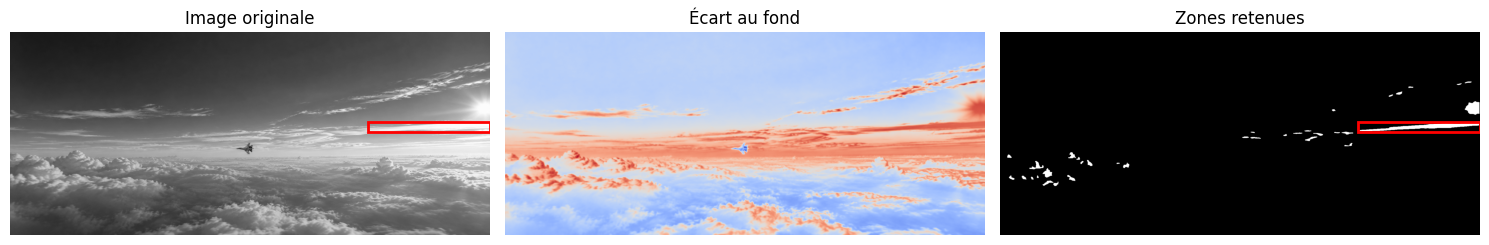

In [4]:
# Image Processing parameters (tuning)

import numpy as np
from scipy import ndimage
from PIL import Image
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# --- Paramètres (à ajuster) ---
CHEMIN_IMAGE = "Su_35S_LongRange.png"
SIGMA_BRUIT = 1.5    # lissage du bruit capteur
K_SEUIL = 5.0     # nb d'"écarts-types" de bruit pour qu'un pixel soit anormal
TAILLE_MIN = 50   # px : en dessous = bruit
TAILLE_MAX_FRAC = 0.5    # zone > 50 % de l'image = ciel/sol, pas un avion
EXCLURE_BORD = True    # ignore les zones touchant le bord (sol, vignettage)

# --- 1. Chargement en float ---
image = np.asarray(Image.open(CHEMIN_IMAGE).convert("L"), dtype=np.float64)
h, w = image.shape

# --- 2. Lissage + estimation du fond (le ciel) ---
lisse = ndimage.gaussian_filter(image, SIGMA_BRUIT)
fond = ndimage.gaussian_filter(image, max(h, w) / 10)  # flou très large = fond seul
ecart = lisse - fond

# --- 3. Seuil automatique robuste (MAD = écart absolu médian) ---
mediane = np.median(ecart)
bruit = max(1.4826 * np.median(np.abs(ecart - mediane)), 1.0)
masque = np.abs(ecart - mediane) > K_SEUIL * bruit  # sombre OU clair (IR)

# --- 4. Nettoyage morphologique ---
masque = ndimage.binary_opening(masque, structure=np.ones((3, 3)))
masque = ndimage.binary_closing(masque, structure=np.ones((5, 5)))
masque = ndimage.binary_fill_holes(masque)

# --- 5. Étiquetage + filtrage par boolean indexing ---
etiquettes, nb_zones = ndimage.label(masque)
tailles = np.bincount(etiquettes.ravel())  # tailles[k] = nb de pixels de la zone k

valide = (tailles >= TAILLE_MIN) & (tailles <= TAILLE_MAX_FRAC * image.size)
valide[0] = False  # l'étiquette 0 = fond
if EXCLURE_BORD:
    bord = np.concatenate([etiquettes[0], etiquettes[-1],
                           etiquettes[:, 0], etiquettes[:, -1]])
    valide[bord] = False

masque_final = valide[etiquettes]  # table de correspondance : une seule ligne
ids_valides = np.flatnonzero(valide)

# --- 6. Décision ---
presence = ids_valides.size > 0
print(f"Bruit estimé : {bruit:.2f} | zones brutes : {nb_zones} | zones valides : {ids_valides.size}")
print(f"Présence d'un objet : {presence}")

if presence:
    id_max = ids_valides[np.argmax(tailles[ids_valides])]
    boite = ndimage.find_objects(etiquettes)[id_max - 1]
    snr = np.abs(ecart[etiquettes == id_max] - mediane).mean() / bruit
    print(f"Plus grande zone : {tailles[id_max]} px, boîte {boite}, SNR ≈ {snr:.1f}")

# --- 7. Visualisation ---
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(image, cmap="gray")
axes[0].set_title("Image originale")
axes[1].imshow(ecart, cmap="coolwarm")
axes[1].set_title("Écart au fond")
axes[2].imshow(masque_final, cmap="gray")
axes[2].set_title("Zones retenues")
if presence:
    ys, xs = boite
    for ax in (axes[0], axes[2]):
        ax.add_patch(Rectangle((xs.start - 0.5, ys.start - 0.5),
                               xs.stop - xs.start, ys.stop - ys.start,
                               edgecolor="red", facecolor="none", linewidth=2))
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.savefig("resultat_detection.png", dpi=150)
plt.show()